# Liver: full composition, spatial organisation and prediction

Run all 24 ROIs and eight held-out mice with the published selected settings.
One shared CNN supplies the K=6 partition. Prediction uses five-seed,
ROI-mean GraphSAGE models; interpretation uses separate patch-pooled models
and 50-step integrated gradients.

**Measured full-fit local runtime: 48 min 47 s**, using an RTX 4070 SUPER
for the CNN and CPU for the GNNs. Colab planning estimate: 1–2.5 h with a T4;
installation and first downloads are excluded. A replay using completed
model checkpoints is faster and does not measure full training. Stage times
are saved below.
CPU-only CNN training takes longer. In Colab, select **Runtime → Change
runtime type → T4 GPU**; restart if the setup cell requests it.

Saved paper values are labelled references. Fresh CNN fits can change cluster
numbers and downstream values. [Supplementary controls](mantpy_liver_controls.ipynb)
and the [exact permutation test](mantpy_liver_permutation.ipynb) are separate.

In [1]:
from pathlib import Path
import hashlib
from urllib.request import urlopen

_SETUP = Path("experiment_setup.py")
_SETUP_SHA256 = "6faab2e74f2559b2cc76cbb5b0323215a58e15ab2fb355050c55822de4214175"
if not _SETUP.exists():
    with urlopen("https://raw.githubusercontent.com/moeghaf/mantpy_reproducibility/mantpy-api-v1.1.0/notebooks/experiments/experiment_setup.py", timeout=90) as response:
        _setup_bytes = response.read()
    if hashlib.sha256(_setup_bytes).hexdigest() != _SETUP_SHA256:
        raise RuntimeError("Downloaded setup checksum does not match this notebook.")
    _setup_temp = _SETUP.with_name(_SETUP.name + ".download")
    _setup_temp.write_bytes(_setup_bytes)
    _setup_temp.replace(_SETUP)
if hashlib.sha256(_SETUP.read_bytes()).hexdigest() != _SETUP_SHA256:
    raise RuntimeError("Use the setup file matching this notebook release.")
from experiment_setup import prepare_experiment
ASSETS = prepare_experiment("liver")


site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1031 10:24:40.574000 34428 torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Liver files and matching Mantpy APIs verified.


In [2]:
import os
from pathlib import Path
import time

import mantpy as mt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from liver_analysis import data, descriptive
import liver_helpers as lh

torch.set_num_threads(min(4, os.cpu_count() or 1))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SELECTED = lh.read_selected()
SEEDS = SELECTED["seeds"]                 # five training seeds: 0–4
RESULTS = Path("results/liver")
RESULTS.mkdir(parents=True, exist_ok=True)
TIMINGS = {}
started = time.perf_counter()
print(f"CNN: {DEVICE}; GNN: CPU; {len(SEEDS)} training seeds")

CNN: cuda; GNN: CPU; 5 training seeds


## 1. Load the full liver cohort

The public Mantpy dataset contains six IMC markers, 24 ROIs and eight mice.
Mouse identity defines the evaluation splits.

In [3]:
stage = time.perf_counter()
liver = mt.datasets.schistosoma_ecm(
    cache_dir=os.environ.get("MANTPY_CACHE"), progressbar=True, verbose=False
)
images, meta = data.cohort(liver)
assert len(images) == 24 and meta.mouse.nunique() == 8
TIMINGS["load_data"] = time.perf_counter() - stage
display(data.mouse_table(meta))

,mouse,group,condition,genotype,n_rois
0,mouse_01,Infected_KO,Infected,KO,4
1,mouse_02,Infected_KO,Infected,KO,4
2,mouse_03,Infected_WT,Infected,WT,4
3,mouse_04,Infected_WT,Infected,WT,4
4,mouse_05,Naive_KO,Naive,KO,2
5,mouse_06,Naive_KO,Naive,KO,2
6,mouse_07,Naive_WT,Naive,WT,2
7,mouse_08,Naive_WT,Naive,WT,2


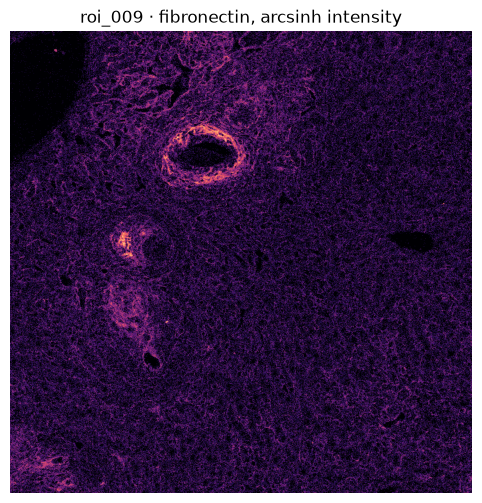

In [4]:
roi = data.REPRESENTATIVE["Infected_WT"]
plt.figure(figsize=(6, 6))
plt.imshow(np.arcsinh(images[roi][0]), cmap="magma")
plt.title(f"{roi} · fibronectin, arcsinh intensity")
plt.axis("off")
plt.show()

## 2. Normalize and extract patches

Use the same label-free cohort preprocessing as the paper. This evaluation
is conditional on a cohort-defined ECM partition. It does not hold the
entire image-to-cluster pipeline out by mouse; the separate controls do that.

In [5]:
stage = time.perf_counter()
norm, bounds = data.normalise(images)      # pooled arcsinh / marker 99.5th percentile
nodes = data.patch_features(norm, meta)   # Mantpy: 10-pixel mean + population SD
nodes["signal"] = data.signal_mask(nodes) # cohort-standardized two-cluster background
windows = lh.make_windows(norm, nodes, patch_size=SELECTED["patch_size"])
TIMINGS["preprocess"] = time.perf_counter() - stage
print(f"{len(nodes):,} complete patches; {int(nodes.signal.sum()):,} signal patches")
display(pd.DataFrame({"marker": data.MARKERS, "bound": bounds}))

240,000 complete patches; 107,732 signal patches


,marker,bound
0,Fibronectin,2.776472
1,Pan-laminin,2.491780
2,CollagenIV,2.312438
3,VersicanV0V1,2.312438
4,CollagenI,3.179785
5,HeparanSulfate,2.491780


## 3. Fit one shared CNN and K=6 partition

The selected encoder uses two convolutional blocks, 96 latent features,
200 contrastive epochs, batch size 1,024 and seed 0. Its embeddings are
standardized once before K-means. No search is run.

`fresh` uses the new encoder fit throughout. Choose `paper` explicitly to
evaluate the classifiers on the deposited partition. Both modes still fit
the selected CNN here, so its fresh output remains inspectable.

In [6]:
PARTITION_MODE = "fresh"                  # "fresh" or explicitly "paper"
display(pd.Series(SELECTED["cnn"], name="selected CNN settings"))

latent_dim          96.0000
projection_dim      64.0000
temperature          0.1000
epochs             200.0000
batch_size        1024.0000
lr                   0.0003
weight_decay         0.0001
Name: selected CNN settings, dtype: float64

In [7]:
stage = time.perf_counter()
cnn, raw_embedding, losses, cnn_record = lh.fit_cnn_cached(
    windows, seed=0, config=SELECTED["cnn"], output_dir=RESULTS, device=DEVICE
)
embedding, labels = lh.cluster_embedding(raw_embedding, seed=0, K=6)
TIMINGS["shared_seed0_cnn"] = time.perf_counter() - stage
del cnn, embedding
if torch.cuda.is_available():
    torch.cuda.empty_cache()

GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


You are using a CUDA device ('NVIDIA GeForce RTX 4070 SUPER') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


...

Trainable params: 60.6 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 60.6 K                                                                                               
Total estimated model params size (MB): 0.243                                                                      
Modules in train mode: 14                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

site-packages\rich\live.py:260: UserWarning: install "ipywidgets" 
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
site-packages\pytorch_lightning\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=27` in the `DataLoader` to improve performance.


site-packages\torch\autograd\graph.py:979: 
UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 
'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at 
https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. 
(Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass

`Trainer.fit` stopped: `max_epochs=200` reached.


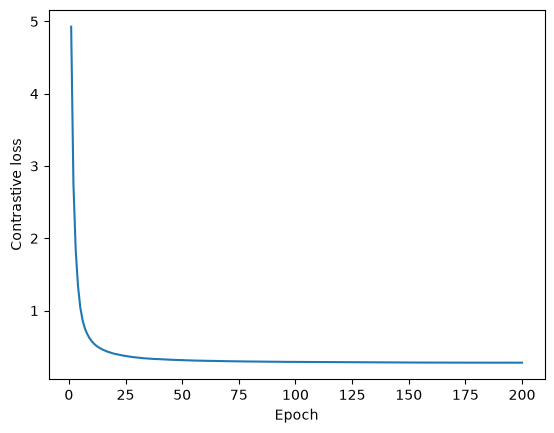

In [8]:
plt.plot(np.arange(1, len(losses) + 1), losses)
plt.xlabel("Epoch")
plt.ylabel("Contrastive loss")
plt.show()

In [9]:
nodes = lh.use_partition(nodes, labels, mode=PARTITION_MODE)
partition_dir = RESULTS / PARTITION_MODE
partition_dir.mkdir(parents=True, exist_ok=True)
nodes.to_csv(partition_dir / "nodes.csv.gz", index=False)
meta.to_csv(partition_dir / "metadata.csv", index=False)
lh.write_json(partition_dir / "partition.json", {
    "mode": PARTITION_MODE,
    "source": "fresh selected seed-0 CNN" if PARTITION_MODE == "fresh" else "deposited paper partition",
    "nodes_sha256": lh.file_hash(partition_dir / "nodes.csv.gz"),
    "metadata_sha256": lh.file_hash(partition_dir / "metadata.csv"),
    "cnn_identity": cnn_record["identity"],
    "library_versions": lh.environment(),
    "marker_bounds": bounds.tolist(),
})
remodelled = descriptive.infection_cluster(nodes)["cluster"]
print(f"Partition: {PARTITION_MODE}; infection-associated cluster: ECM {remodelled}")
display(nodes.loc[nodes.signal].groupby("cluster").size().rename("patches"))

Partition: fresh; infection-associated cluster: ECM 5


python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  

cluster
0    32975
1    23071
2    20958
3    12599
4    10361
5     7768
Name: patches, dtype: int64

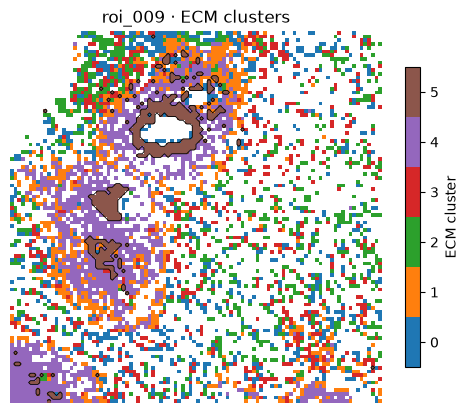

In [10]:
lh.show_patch_map(nodes, roi, outline=remodelled)

## 4. Composition and spatial organisation

Compute per-mouse patch fractions and weight mice equally within each group.
Identify the remodelled cluster with the published abundance rule rather
than assigning it a fixed cluster number.

python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
python\functools.py:909: ImplicitModificationWarning: Transforming to str index.
  

cluster,group,0,1,2,3,4,5
mouse,,,,,,,
mouse_01,Infected_KO,0.251874,0.516121,0.048106,0.085122,0.068796,0.029983
mouse_02,Infected_KO,0.523823,0.195962,0.070382,0.094677,0.070505,0.044651
mouse_03,Infected_WT,0.170985,0.134570,0.245042,0.159149,0.202602,0.087652
mouse_04,Infected_WT,0.208256,0.161465,0.175963,0.146199,0.107086,0.201030
mouse_05,Naive_KO,0.511709,0.042715,0.335863,0.065698,0.044016,0.000000
mouse_06,Naive_KO,0.354995,0.095257,0.462676,0.050784,0.036288,0.000000
mouse_07,Naive_WT,0.178784,0.121641,0.407921,0.198020,0.093635,0.000000
mouse_08,Naive_WT,0.190345,0.117184,0.453211,0.190132,0.048915,0.000213


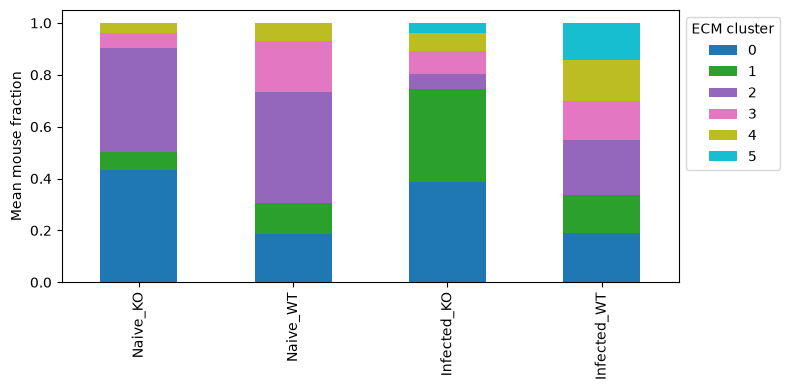

In [11]:
# Mantpy pools patch counts within each mouse; infection-cluster selection stays local.
stage = time.perf_counter()
fractions = descriptive.mouse_fractions(nodes)
profiles = descriptive.marker_profiles(nodes)
fractions.to_csv(partition_dir / "composition_per_mouse.csv")
profiles.to_csv(partition_dir / "marker_profiles.csv", index=False)
display(fractions)
fractions.groupby("group")[list(range(6))].mean().reindex(data.GROUPS).plot(
    kind="bar", stacked=True, figsize=(8, 4), colormap="tab10"
)
plt.ylabel("Mean mouse fraction")
plt.xlabel("")
plt.legend(title="ECM cluster", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()
TIMINGS["composition"] = time.perf_counter() - stage

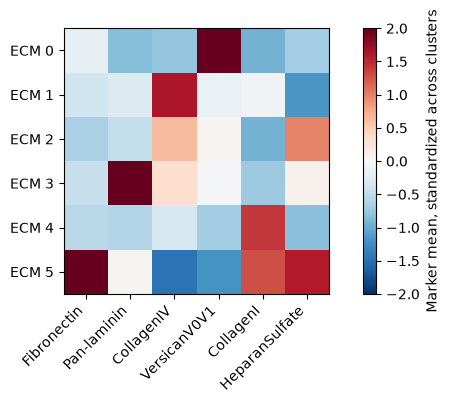

In [12]:
matrix = profiles[[f"z_mean_{marker}" for marker in data.MARKERS]].to_numpy()
fig, ax = plt.subplots(figsize=(7, 4))
image = ax.imshow(matrix, cmap="RdBu_r", vmin=-2, vmax=2)
ax.set_xticks(range(6), data.MARKERS, rotation=45, ha="right")
ax.set_yticks(range(6), [f"ECM {k}" for k in range(6)])
fig.colorbar(image, ax=ax, label="Marker mean, standardized across clusters")
plt.tight_layout()
plt.show()

,cluster_a,cluster_b,delta_equal_mouse,delta_pooled_tissue,F_mouse_01,F_mouse_02,F_mouse_03,F_mouse_04,O_mouse_01,O_mouse_02,O_mouse_03,O_mouse_04,involves_infection_cluster
5,0,5,0.717120,0.766570,-1.779757,-1.751665,-2.494676,-2.470987,164.0,773.0,180.0,704.0,True
10,1,5,0.144200,-0.028536,-1.030209,-0.541620,-0.752273,-1.107955,565.0,669.0,474.0,1404.0,True
14,2,5,4.225219,4.360917,0.359641,0.009242,-3.861827,-4.219727,138.0,352.0,100.0,177.0,True
17,3,5,2.239961,2.085013,0.189345,-0.460147,-2.525484,-2.225240,217.0,342.0,164.0,586.0,True
19,4,5,0.836024,0.965392,1.760145,0.577956,0.671824,-0.005772,521.0,523.0,1915.0,1999.0,True
20,5,5,1.241436,1.333514,4.586043,4.043179,3.664423,2.481927,1610.0,3658.0,6594.0,21048.0,True


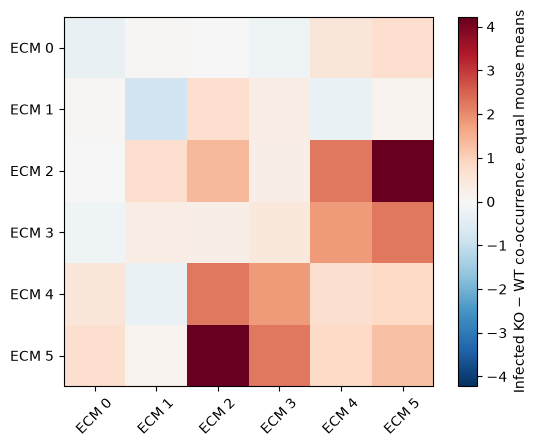

In [13]:
# Public co-occurrence returns mouse-pooled counts/expected values; independent paper checks remain local.
stage = time.perf_counter()
adatas, graphs = lh.make_graphs(nodes, meta, graph_type="delaunay")
cooccurrence = descriptive.cooccurrence(
    nodes, graphs=adatas, infection_cluster_id=remodelled
)
for name, table in cooccurrence.items():
    table.to_csv(partition_dir / f"cooccurrence_{name}.csv", index=False)
display(cooccurrence["pairs"].query("involves_infection_cluster"))
delta = descriptive.pair_matrix(cooccurrence["pairs"], "delta_equal_mouse")
plt.imshow(delta, cmap="RdBu_r", vmin=-np.nanmax(abs(delta)), vmax=np.nanmax(abs(delta)))
plt.xticks(range(6), [f"ECM {k}" for k in range(6)], rotation=45)
plt.yticks(range(6), [f"ECM {k}" for k in range(6)])
plt.colorbar(label="Infected KO − WT co-occurrence, equal mouse means")
plt.show()
TIMINGS["graphs_and_cooccurrence"] = time.perf_counter() - stage

,radius_px,min_nodes,mouse,group,n_components,median_n_nodes,median_mean_degree,total_infection_cluster_nodes_retained
32,40.0,5,mouse_01,Infected_KO,7,14.0,6.000000,539
33,40.0,5,mouse_02,Infected_KO,10,11.5,7.250000,1052
34,40.0,5,mouse_03,Infected_WT,6,142.5,20.716607,1626
35,40.0,5,mouse_04,Infected_WT,9,46.0,13.826087,4428
36,40.0,5,mouse_05,Naive_KO,0,NaN,NaN,0
37,40.0,5,mouse_06,Naive_KO,0,NaN,NaN,0
38,40.0,5,mouse_07,Naive_WT,0,NaN,NaN,0
39,40.0,5,mouse_08,Naive_WT,0,NaN,NaN,0


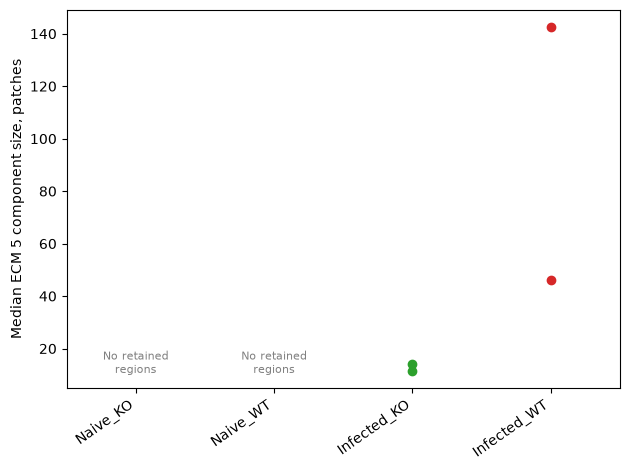

In [14]:
# Public component_summary uses radius40/min5 and pools components within mice.
stage = time.perf_counter()
regions = descriptive.subgraphs(nodes, adatas, cluster=remodelled)
for name, table in regions.items():
    table.to_csv(partition_dir / f"connected_regions_{name}.csv", index=False)
primary_regions = regions["sensitivity"].query("radius_px == 40 and min_nodes == 5")
display(primary_regions)
fig, ax = plt.subplots()
for position, group in enumerate(data.GROUPS):
    sub = primary_regions.loc[primary_regions.group == group]
    values = sub.median_n_nodes.to_numpy(float)
    finite = np.isfinite(values)
    if finite.any():
        ax.scatter(np.full(finite.sum(), position), values[finite],
                   color=plt.get_cmap("tab10")(position), label=group)
    else:
        ax.text(position, 0.03, "No retained\nregions",
                transform=ax.get_xaxis_transform(), ha="center", va="bottom",
                fontsize=8, color="grey")
ax.set_xticks(range(len(data.GROUPS)), data.GROUPS, rotation=35, ha="right")
ax.set_xlim(-0.5, len(data.GROUPS) - 0.5)
ax.set_ylabel(f"Median ECM {remodelled} component size, patches")
fig.tight_layout()
plt.show()
TIMINGS["connected_regions"] = time.perf_counter() - stage

## 5. Predict infection in every held-out mouse

Fit the fixed two-layer GraphSAGE model for all eight mouse folds and
seeds 0–4. Standardization and class weights use only training ROIs.
The weighted loss is averaged within each ROI, then across ROIs.
Average seed probabilities within an ROI and ROI probabilities within a mouse.

In [15]:
# Each local outer fold calls mt.nn.train_node_classifier with ROI-mean loss.
display(pd.Series(SELECTED["fixed_gnn"], name="fixed GraphSAGE settings"))
stage = time.perf_counter()
prediction = lh.run_outer_folds(
    graphs, meta, seeds=SEEDS, config=SELECTED["fixed_gnn"],
    objective="roi_mean", output_dir=partition_dir / "prediction"
)
lh.save_outer_outputs(prediction, partition_dir / "prediction")
prediction_metrics = lh.metric_table(prediction["ensemble"], "GraphSAGE · ROI-mean")
TIMINGS["prediction_40_fits"] = time.perf_counter() - stage
display(prediction_metrics)
display(prediction["ensemble"])

graph_type         delaunay
conv                   sage
hidden_dim               64
n_layers                  2
aggr                   mean
norm                   none
residual              False
activation             relu
dropout                 0.2
input_dropout           0.0
optimizer              adam
lr                    0.005
weight_decay         0.0001
epochs                  120
lr_schedule        constant
class_weight           True
label_smoothing         0.0
Name: fixed GraphSAGE settings, dtype: object

roi_mean: mouse_01, seed 0, 41.2s


roi_mean: mouse_01, seed 1, 39.9s


roi_mean: mouse_01, seed 2, 38.7s


roi_mean: mouse_01, seed 3, 38.2s


...

roi_mean: mouse_08, seed 3, 45.9s


roi_mean: mouse_08, seed 4, 46.2s


Completed held-out mouse mouse_08.


,model,level,n,correct,accuracy,ROC_AUC,Brier,log_loss
0,GraphSAGE · ROI-mean,ROI,24,20,0.833333,0.976562,0.141156,0.461694
1,GraphSAGE · ROI-mean,mouse,8,8,1.000000,1.000000,0.129358,0.443555


,roi,mouse,group,true_infected,P_infected
0,roi_001,mouse_01,Infected_KO,1,0.700510
1,roi_002,mouse_01,Infected_KO,1,0.726171
2,roi_003,mouse_01,Infected_KO,1,0.746266
3,roi_004,mouse_01,Infected_KO,1,0.727484
4,roi_005,mouse_02,Infected_KO,1,0.588742
5,roi_006,mouse_02,Infected_KO,1,0.704233
6,roi_007,mouse_02,Infected_KO,1,0.729016
7,roi_008,mouse_02,Infected_KO,1,0.469947
8,roi_009,mouse_03,Infected_WT,1,0.640610
9,roi_010,mouse_03,Infected_WT,1,0.374937


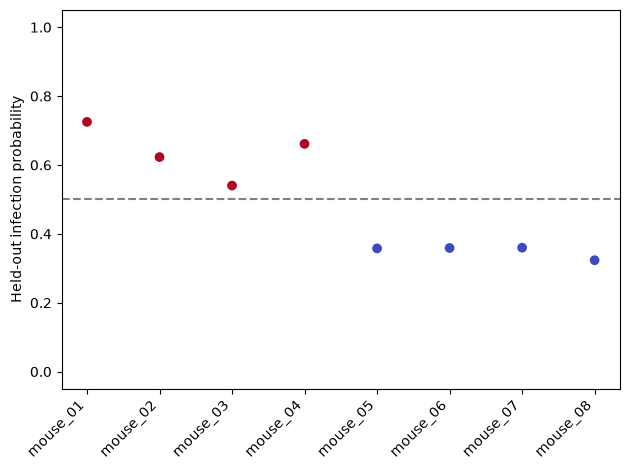

In [16]:
mouse_prediction = prediction["ensemble"].groupby("mouse", as_index=False).agg(
    true_infected=("true_infected", "first"), P_infected=("P_infected", "mean")
)
plt.scatter(mouse_prediction.mouse, mouse_prediction.P_infected,
            c=mouse_prediction.true_infected, cmap="coolwarm", vmin=0, vmax=1)
plt.axhline(0.5, color="grey", linestyle="--")
plt.ylabel("Held-out infection probability")
plt.xticks(rotation=45, ha="right")
plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

## 6. Composition-only reference

Refit logistic regression using the retained C for each mouse fold.
Only training fractions enter its scaler and model. The inner C search
is omitted; the fold-specific selections are visible in the companion JSON.

In [17]:
stage = time.perf_counter()
lr_prediction = lh.composition_lr(graphs, meta, SELECTED["composition_lr"])
lr_prediction.to_csv(partition_dir / "composition_lr_predictions.csv", index=False)
lr_metrics = lh.metric_table(lr_prediction, "Composition LR · selected fold C")
metrics = pd.concat([prediction_metrics, lr_metrics], ignore_index=True)
metrics.to_csv(partition_dir / "prediction_metrics.csv", index=False)
display(metrics)
TIMINGS["composition_lr"] = time.perf_counter() - stage

,model,level,n,correct,accuracy,ROC_AUC,Brier,log_loss
0,GraphSAGE · ROI-mean,ROI,24,20,0.833333,0.976562,0.141156,0.461694
1,GraphSAGE · ROI-mean,mouse,8,8,1.000000,1.000000,0.129358,0.443555
2,Composition LR · selected fold C,ROI,24,18,0.750000,0.843750,0.160895,0.482355
3,Composition LR · selected fold C,mouse,8,6,0.750000,0.937500,0.135921,0.414109


## 7. Explain every held-out ROI

Refit 40 separate models with the original patch-pooled objective for
interpretation. For all 24 ROIs, compute signed integrated gradients
towards the mean infected logit, using a zero baseline in standardized
feature space and 50 integration steps. Average signed attributions over
the five seeds, then sum their absolute values per node.

patch_sum: mouse_01, seed 0, 37.0s


patch_sum: mouse_01, seed 1, 36.6s


patch_sum: mouse_01, seed 2, 36.2s


patch_sum: mouse_01, seed 3, 36.8s


patch_sum: mouse_01, seed 4, 36.9s


...

patch_sum: mouse_08, seed 1, 45.3s


patch_sum: mouse_08, seed 2, 44.0s


patch_sum: mouse_08, seed 3, 46.3s


patch_sum: mouse_08, seed 4, 47.0s


Completed held-out mouse mouse_08.


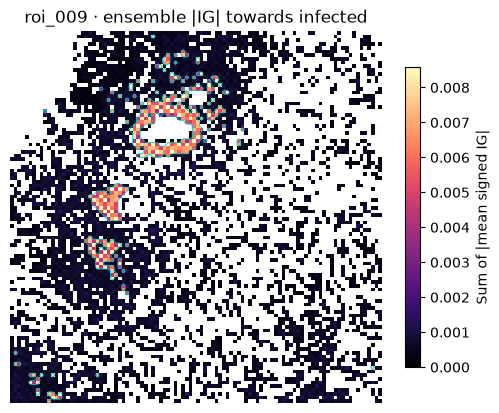

In [18]:
# Explanation fits use the separate patch-pooled loss and public signed IG.
stage = time.perf_counter()
explanation = lh.run_outer_folds(
    graphs, meta, seeds=SEEDS, config=SELECTED["fixed_gnn"],
    objective="patch_sum", output_dir=partition_dir / "explanation",
    explain=True, steps=SELECTED["ig_steps"]
)
lh.save_outer_outputs(explanation, partition_dir / "explanation")
assert explanation["attributions"].roi.nunique() == 24
assert len(explanation["ig_residuals"]) == 24 * len(SEEDS)
TIMINGS["explanation_40_fits_120_ig"] = time.perf_counter() - stage
lh.show_ig(explanation["attributions"], roi, remodelled)

In [19]:
localisation = descriptive.ig_localisation(
    explanation["attributions"], infection_cluster_id=remodelled
)
localisation.to_csv(partition_dir / "ig_localisation.csv", index=False)
display(localisation.query("is_infection_cluster"))
display(explanation["ig_residuals"].groupby("mouse").completeness_residual.agg(
    ["min", "max", "mean"]
))

,roi,mouse,group,cluster,is_infection_cluster,n_cluster_nodes,n_nodes,pearson_r_abs_ig_vs_membership
5,roi_001,mouse_01,Infected_KO,5,True,0,4366,NaN
11,roi_002,mouse_01,Infected_KO,5,True,294,5530,0.958989
17,roi_003,mouse_01,Infected_KO,5,True,258,4193,0.948698
23,roi_004,mouse_01,Infected_KO,5,True,32,5389,0.873778
29,roi_005,mouse_02,Infected_KO,5,True,73,7424,0.890850
35,roi_006,mouse_02,Infected_KO,5,True,353,7229,0.954324
41,roi_007,mouse_02,Infected_KO,5,True,657,7213,0.957495
47,roi_008,mouse_02,Infected_KO,5,True,5,2501,0.727872
53,roi_009,mouse_03,Infected_WT,5,True,369,4616,0.949614
59,roi_010,mouse_03,Infected_WT,5,True,1,4160,NaN


,min,max,mean
mouse,,,
mouse_01,-0.003135,0.013815,0.003628
mouse_02,-0.011257,0.007499,0.000171
mouse_03,-0.002667,0.010602,0.002294
mouse_04,-0.026502,0.008129,-0.003886
mouse_05,-0.013663,0.006886,-0.003951
mouse_06,-0.015028,0.003642,-0.002731
mouse_07,-0.005145,0.005393,0.000338
mouse_08,-0.001857,0.007806,0.002890


## 8. Export timings and compare labelled references

The table below contains deposited paper values for context. The tables
above contain the new fits. Supplementary selections, controls and the
exact permutation test are available in the linked notebooks.

In [20]:
reference = pd.DataFrame([
    {"analysis": "Fixed GraphSAGE, mouse accuracy", "paper_reference": SELECTED["paper_reference"]["fixed_mouse_accuracy"]},
    {"analysis": "Fixed GraphSAGE, mouse ROC-AUC", "paper_reference": SELECTED["paper_reference"]["fixed_mouse_auc"]},
    {"analysis": "Fixed GraphSAGE, correctly classified ROIs", "paper_reference": SELECTED["paper_reference"]["fixed_correct_rois"]},
    {"analysis": "Composition LR, mouse ROC-AUC", "paper_reference": SELECTED["paper_reference"]["composition_lr_mouse_auc"]},
])
display(reference)
TIMINGS["notebook_total"] = time.perf_counter() - started
timing_table = pd.DataFrame({"stage": list(TIMINGS), "seconds": list(TIMINGS.values())})
timing_table.to_csv(partition_dir / "timings.csv", index=False)
lh.write_json(partition_dir / "run.json", {
    "partition_mode": PARTITION_MODE, "config": SELECTED,
    "library_versions": lh.environment(), "device": DEVICE,
    "seeds": SEEDS, "n_rois": len(meta), "n_mice": meta.mouse.nunique(),
    "timings_seconds": TIMINGS,
})
display(timing_table)
print(f"Results: {partition_dir.resolve()}")

,analysis,paper_reference
0,"Fixed GraphSAGE, mouse accuracy",1.0000
1,"Fixed GraphSAGE, mouse ROC-AUC",1.0000
2,"Fixed GraphSAGE, correctly classified ROIs",20.0000
3,"Composition LR, mouse ROC-AUC",0.9375


,stage,seconds
0,load_data,1.593655
1,preprocess,6.394829
2,shared_seed0_cnn,286.915442
3,composition,0.261406
4,graphs_and_cooccurrence,10.160621
5,connected_regions,10.680110
6,prediction_40_fits,1638.841911
7,composition_lr,0.048774
8,explanation_40_fits_120_ig,1669.828600
9,notebook_total,3637.406748


Results: .\outputs\notebook_api_implementation\full_after\workspaces\liver\results\liver\fresh
